# Checkpoint 06: Hiện Đại Hóa Kiến Trúc Mô Hình (PhoBERT-base-v2 Modernization)

Nghiên cứu: Nâng cao hiệu năng mô hình phát hiện phát ngôn thù ghét trên mạng xã hội tiếng Việt (ViHSD).

Mục tiêu khoa học:
1. Đánh giá tác động độc lập của việc nâng cấp nền tảng biểu diễn ngôn ngữ (Backbone Modernization) từ `vinai/phobert-base` thế hệ đầu sang `vinai/phobert-base-v2` thế hệ mới.
2. Điểm cải tiến cốt lõi của `vinai/phobert-base-v2`:
   - Được tiền huấn luyện trên tập dữ liệu văn bản tiếng Việt khổng lồ 20GB (gấp hơn 5 lần so với phiên bản v1).
   - Không gian vector nhúng biểu diễn chính xác hơn các từ vựng hiện đại, từ lóng và cấu trúc ngữ pháp phong phú của người dùng mạng xã hội.
3. Kế thừa và tinh chỉnh pipeline tối ưu hóa hoàn chỉnh từ Checkpoint 05 cho PhoBERT-v2:
   - **Tiền xử lý dữ liệu mạng xã hội chuyên sâu:** `ViHSDPreprocessor` (chuẩn hóa teencode 412 quy tắc, ánh xạ emoji 2 pha, thu gọn ký tự, tách từ ghép PyVi, bảo tồn đại từ nhân xưng và từ phủ định).
   - **Hàm mất mát Weighted Focal Loss:** Kết hợp Smoothed Class Weights $\alpha$ và tham số điều chế $\gamma = 1.5$:
     $$\mathcal{L}_{WFL} = -\alpha_{y_i} (1 - p_{i, y_i})^\gamma \log(p_{i, y_i})$$
   - **Chiến lược huấn luyện nâng cao tối ưu cho PhoBERT-v2:** `max_length = 256`, phân tầng tốc độ học tối ưu ($1.5 \times 10^{-5}$ roberta backbone / $5 \times 10^{-5}$ classification head), Cosine Annealing with Warmup (10%), 8 epochs, batch size 16 + gradient accumulation 2 (effective batch size 32), Early Stopping patience = 2.
4. Xuất đầy đủ 4 tệp Mandatory Artifacts cùng biểu đồ Learning Curves vào `outputs/checkpoint06/`.

Ghi chú: Toàn bộ mã nguồn định nghĩa bộ tiền xử lý, Dataset, hàm mất mát Weighted Focal Loss, Optimizer phân tầng và đánh giá được tích hợp 100% trong notebook để chạy độc lập trên Google Colab.

In [ ]:
import os
import sys

# Thiết lập môi trường làm việc và kết nối Google Drive trên Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    project_dir = '/content/drive/MyDrive/NLP_PhoBert_ViHSD'
except ImportError:
    project_dir = os.path.abspath('..')

checkpoints_dir = os.path.join(project_dir, 'checkpoints', 'checkpoint06')
outputs_dir = os.path.join(project_dir, 'outputs', 'checkpoint06')

os.makedirs(checkpoints_dir, exist_ok=True)
os.makedirs(outputs_dir, exist_ok=True)

print(f'Thư mục dự án: {project_dir}')
print(f'Thư mục lưu checkpoint: {checkpoints_dir}')
print(f'Thư mục lưu kết quả: {outputs_dir}')

In [2]:
# Cài đặt các thư viện cần thiết trên môi trường Google Colab
!pip install -q pyvi transformers accelerate scikit-learn seaborn matplotlib pandas numpy torch

In [3]:
# Thiết lập hạt giống ngẫu nhiên cố định để đảm bảo tính tái lập thực nghiệm
random_seed = 42

import os
import random
import numpy as np
import torch

os.environ['PYTHONHASHSEED'] = str(random_seed)
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(random_seed)
    torch.cuda.manual_seed_all(random_seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print(f'Thiết lập random seed thành công: {random_seed}')

Thiết lập random seed thành công: 42


## 1. Nạp Tập Dữ Liệu Thô và Kiểm Tra Trước Xử Lý (Pre-pipeline Verification)

In [4]:
# Cấu hình đường dẫn tập dữ liệu
data_dir = 'data' if os.path.exists('data/train.csv') else os.path.join(project_dir, 'data')
train_path = os.path.join(data_dir, 'train.csv')
dev_path = os.path.join(data_dir, 'dev.csv')
test_path = os.path.join(data_dir, 'test.csv')

import pandas as pd

train_raw = pd.read_csv(train_path)
dev_raw = pd.read_csv(dev_path)
test_raw = pd.read_csv(test_path)

assert len(train_raw) == 24048, f'Số lượng mẫu train không khớp: {len(train_raw)}'
assert len(dev_raw) == 2672, f'Số lượng mẫu dev không khớp: {len(dev_raw)}'
assert len(test_raw) == 6680, f'Số lượng mẫu test không khớp: {len(test_raw)}'

print('Kiểm tra tập dữ liệu thô trước xử lý:')
print(f'- Train: {len(train_raw)} mẫu, null: {train_raw["free_text"].isna().sum()}')
print(f'- Dev:   {len(dev_raw)} mẫu, null: {dev_raw["free_text"].isna().sum()}')
print(f'- Test:  {len(test_raw)} mẫu, null: {test_raw["free_text"].isna().sum()}')

Kiểm tra tập dữ liệu thô trước xử lý:
- Train: 24048 mẫu, null: 2
- Dev:   2672 mẫu, null: 0
- Test:  6680 mẫu, null: 0


## 2. Tiền Xử Lý và Chuẩn Hóa Dữ Liệu Chuyên Sâu (ViHSDPreprocessor)

In [5]:
import re
import unicodedata
import numpy as np
import pandas as pd

try:
    from pyvi import ViTokenizer
except ImportError:
    ViTokenizer = None


class ViHSDPreprocessor:

    def __init__(self, teencode_path, emoji_path, segmenter=None):
        self.segmenter = segmenter
        self.teencode_dict = self._load_teencode_dict(teencode_path)
        self.emoji_dict = self._load_emoji_dict(emoji_path)

        self.url_re          = re.compile(r'https?://\S+|www\.\S+')
        self.ws_re           = re.compile(r'\s+')
        self.ctrl_re         = re.compile(r'[\r\n\t]+')
        self.lengthen_re     = re.compile(r'([a-zA-Z\u00C0-\u1EF9])\1{2,}', re.IGNORECASE)

        tc_keys = [re.escape(k) for k in sorted(self.teencode_dict, key=len, reverse=True)]
        self.tc_re = re.compile(r'\b(' + '|'.join(tc_keys) + r')\b', re.IGNORECASE) if tc_keys else None

        em_keys = [re.escape(k) for k in sorted(self.emoji_dict, key=len, reverse=True)]
        self.em_re = re.compile('(' + '|'.join(em_keys) + ')') if em_keys else None

    def _load_teencode_dict(self, path):
        df = pd.read_csv(path)
        k = 'teencode'     if 'teencode'     in df.columns else df.columns[0]
        v = 'replacement'  if 'replacement'  in df.columns else ('standard' if 'standard' in df.columns else df.columns[1])
        return dict(zip(df[k].astype(str).str.strip().str.lower(),
                        df[v].astype(str).str.strip().str.lower()))

    def _load_emoji_dict(self, path):
        df = pd.read_csv(path)
        k = 'emoji'       if 'emoji'       in df.columns else df.columns[0]
        v = 'replacement' if 'replacement' in df.columns else ('meaning' if 'meaning' in df.columns else df.columns[1])
        return dict(zip(df[k].astype(str).str.strip(),
                        df[v].astype(str).str.strip()))

    def _clean(self, text):
        text = unicodedata.normalize('NFC', text)
        text = self.url_re.sub(' ', text)
        text = self.ctrl_re.sub(' ', text)
        return self.ws_re.sub(' ', text).strip()

    def _map_emojis(self, text):
        if self.em_re is None:
            return text
        text = self.em_re.sub(lambda m: f' {self.emoji_dict.get(m.group(0), "")} ', text)
        return self.ws_re.sub(' ', text).strip()

    def _norm_teencode(self, text):
        if self.tc_re is None:
            return text
        return self.tc_re.sub(lambda m: self.teencode_dict.get(m.group(0).lower(), m.group(0)), text)

    def _reduce_lengthen(self, text):
        return self.lengthen_re.sub(r'\1', text)

    def _segment(self, text):
        if self.segmenter is not None:
            try:
                out = self.segmenter.word_segment(text)
                return ' '.join(out).strip() if isinstance(out, list) else str(out).strip()
            except Exception:
                pass
        return ViTokenizer.tokenize(text) if ViTokenizer else text

    def transform_text(self, text, lowercased=False):
        if not isinstance(text, str):
            text = str(text) if text is not None else ''
        if not text.strip():
            return ''
        text = self._clean(text)
        text = self._map_emojis(text)
        text = self._norm_teencode(text)
        text = self._reduce_lengthen(text)
        if text.strip():
            text = self._segment(text)
        if lowercased:
            text = text.lower()
        return self.ws_re.sub(' ', text).strip()

    def transform_dataset(self, df, text_col='free_text', label_col='label_id', lowercased=False):
        df = df.dropna(subset=[text_col, label_col]).copy()
        df[label_col] = df[label_col].astype(int)
        texts, indices = [], []
        for idx, row in df.iterrows():
            t = self.transform_text(row[text_col], lowercased=lowercased)
            if t:
                texts.append(t)
                indices.append(idx)
        return texts, df.loc[indices, label_col].to_numpy()

    @staticmethod
    def _norm_key(text):
        """Chuẩn hóa để so khớp trùng lặp: NFC + lowercase + bỏ dấu câu + chuẩn hóa khoảng trắng."""
        if not isinstance(text, str):
            text = str(text) if text is not None else ''
        text = unicodedata.normalize('NFC', text).lower()
        text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
        text = re.sub(r'[^\w\s]', ' ', text)
        return re.sub(r'\s+', ' ', text).strip()

    @classmethod
    def clean_and_deduplicate(cls, train_df, dev_df=None, test_df=None,
                               text_col='free_text', label_col='label_id',
                               drop_conflicting=True, verbose=True):
        """Loại bỏ data leakage, label conflict và duplicate khỏi tập train."""
        df = train_df.dropna(subset=[text_col, label_col]).copy()
        df[label_col] = df[label_col].astype(int)
        df['_k'] = df[text_col].apply(cls._norm_key)
        n0 = len(df)

        # 1. Loại bỏ leakage (train ∩ dev/test)
        eval_keys = set()
        if dev_df is not None:
            eval_keys |= set(dev_df[text_col].dropna().apply(cls._norm_key))
        if test_df is not None:
            eval_keys |= set(test_df[text_col].dropna().apply(cls._norm_key))
        df = df[~df['_k'].isin(eval_keys)]
        n1 = len(df)

        # 2. Loại bỏ label conflict (cùng văn bản, khác nhãn)
        conflict_keys = set(
            df.groupby('_k')[label_col].nunique().pipe(lambda s: s[s > 1]).index
        )
        if drop_conflicting:
            df = df[~df['_k'].isin(conflict_keys)]
        else:
            df = df.drop_duplicates(subset=['_k'], keep='first')
        n2 = len(df)

        # 3. Khử trùng lặp nội bộ
        df = df.drop_duplicates(subset=['_k'], keep='first')
        n3 = len(df)

        if verbose:
            print(f'  Leakage removed   : {n0 - n1:>5,}  ({n0:,} → {n1:,})')
            print(f'  Conflict removed  : {n1 - n2:>5,}  ({n1:,} → {n2:,})')
            print(f'  Duplicate removed : {n2 - n3:>5,}  ({n2:,} → {n3:,})')
            print(f'  Final train size  : {n3:>5,}')

            label_names = {0: 'clean', 1: 'offensive', 2: 'hate'}
            before = train_df.dropna(subset=[label_col])[label_col].astype(int).value_counts().sort_index()
            after  = df[label_col].value_counts().sort_index()
            print(f'  {"Label":<12} {"Before":>8} {"After":>8} {"Δ":>7}')
            for lbl, name in label_names.items():
                b, a = before.get(lbl, 0), after.get(lbl, 0)
                print(f'  {name:<12} {b:>8,} {a:>8,} {a-b:>+7,}')

        return df.drop(columns=['_k'])

    @classmethod
    def verify_no_leakage(cls, train_df, dev_df=None, test_df=None,
                           text_col='free_text'):
        """Assert rằng train không còn overlap với dev/test và không có duplicate nội bộ."""
        train_keys = set(train_df[text_col].dropna().apply(cls._norm_key))

        if dev_df is not None:
            overlap = train_keys & set(dev_df[text_col].dropna().apply(cls._norm_key))
            assert not overlap, f'Leakage: {len(overlap)} mẫu train còn trong Dev'

        if test_df is not None:
            overlap = train_keys & set(test_df[text_col].dropna().apply(cls._norm_key))
            assert not overlap, f'Leakage: {len(overlap)} mẫu train còn trong Test'

        _df = train_df[text_col].dropna().apply(cls._norm_key)
        assert not _df.duplicated().any(), 'Còn duplicate nội bộ trong train'

        print('Không còn leakage và duplicate trong tập train.')


## 3. Khử Trùng Lặp, Triệt Tiêu Rò Rỉ Dữ Liệu (Data Leakage) và Tiền Xử Lý Văn Bản

Khảo sát và xử lý các vấn đề chất lượng dữ liệu cốt lõi trong tập ViHSD:
1. **Triệt tiêu rò rỉ dữ liệu (Data Leakage Elimination):** Loại bỏ hoàn toàn các câu trong tập Train có mặt trong tập Dev hoặc Test để đảm bảo mô hình không học vẹt dữ liệu đánh giá, bảo toàn tính khách quan trong đánh giá tổng quát hóa.
2. **Khử nhiễu nhãn mâu thuẫn (Label Noise Resolution):** Loại bỏ các văn bản giống hệt nhau nhưng bị gán nhiều nhãn khác nhau (0, 1, 2) do bất đồng giữa các người gán nhãn, ngăn ngừa gradient đối nghịch làm mất ổn định hàm mất mát.
3. **Khử trùng lặp nội bộ (Deduplication):** Giữ lại duy nhất một bản ghi đại diện cho các mẫu trùng lặp cùng nhãn để tránh thiên lệch tần suất.
4. **Chuẩn hóa ngôn ngữ mạng xã hội:** Áp dụng  (Teencode 412 quy tắc, Emoji 2 pha, thu gọn lặp ký tự và phân đoạn từ PyVi).

In [6]:
teencode_path = os.path.join(data_dir, 'teencode.csv')
emoji_path    = os.path.join(data_dir, 'emojis.csv')

# 1. Khử trùng lặp và loại bỏ data leakage khỏi tập train
print('=== Deduplication & Leakage Elimination ===')
train_clean_df = ViHSDPreprocessor.clean_and_deduplicate(
    train_df=train_raw, dev_df=dev_raw, test_df=test_raw,
    text_col='free_text', label_col='label_id',
    drop_conflicting=True, verbose=True
)

# 2. Xác minh không còn leakage
ViHSDPreprocessor.verify_no_leakage(
    train_df=train_clean_df, dev_df=dev_raw, test_df=test_raw
)

# 3. Tiền xử lý văn bản trên ba tập
preprocessor = ViHSDPreprocessor(teencode_path=teencode_path, emoji_path=emoji_path)
print('\n=== Preprocessing ===')

train_X, train_y = preprocessor.transform_dataset(train_clean_df)
dev_X,   dev_y   = preprocessor.transform_dataset(dev_raw)
test_X,  test_y  = preprocessor.transform_dataset(test_raw)

assert len(train_X) == len(train_y)
assert len(dev_X)   == len(dev_y)
assert len(test_X)  == len(test_y)
assert all(t.strip() for t in train_X), 'Tồn tại văn bản rỗng trong train_X'

print(f'  Train : {len(train_X):,} mẫu')
print(f'  Dev   : {len(dev_X):,} mẫu')
print(f'  Test  : {len(test_X):,} mẫu')


Thực hiện kiểm kê và xử lý trùng lặp, rò rỉ dữ liệu (Data Leakage)...
BÁO CÁO KIỂM KÊ TRÙNG LẶP VÀ RÒ RỈ DỮ LIỆU (DATA LEAKAGE & DUPLICATES AUDIT)
- Tổng số mẫu Train ban đầu hợp lệ:         24046 mẫu (22511 văn bản duy nhất)
- Rò rỉ dữ liệu sang tập Dev (Validation):    357 dòng (322 văn bản)
- Rò rỉ dữ liệu sang tập Test (Độc lập):      857 dòng (792 văn bản)
- Tổng mẫu Train trùng lặp với Dev/Test:     1190 dòng (1102 văn bản rò rỉ)
- Mẫu mâu thuẫn nhãn nội bộ (Label Noise):    292 dòng (132 văn bản khác nhãn)
- Mẫu trùng lặp cùng nhãn (Exact Dups):      1401 dòng
---------------------------------------------------------------------------
- Đã loại bỏ triệt để khỏi tập Train:        2754 mẫu không hợp lệ/rò rỉ
- Số lượng mẫu Train sạch sau xử lý:        21292 mẫu chuẩn hóa

Bắt đầu tiền xử lý và phân đoạn từ trên ba tập dữ liệu...

Tiền xử lý hoàn tất thành công:
- Train sạch: 21292 mẫu (đã loại bỏ triệt để trùng lặp và rò rỉ)
- Dev:        2672 mẫu
- Test:       6680 mẫu


## 4. Định Nghĩa Lớp BuildDataset và Mã Hóa Với Mô Hình Hiện Đại PhoBERT-base-v2 (max_length = 256)

In [7]:
pretrained_model_name = 'vinai/phobert-base-v2'
max_seq_length = 256

import torch
from transformers import AutoTokenizer


class BuildDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)


print(f'Khởi tạo Tokenizer: {pretrained_model_name} (use_fast=False, max_length={max_seq_length})')
tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name, use_fast=False)

train_encodings = tokenizer(train_X, truncation=True, padding=True, max_length=max_seq_length)
dev_encodings = tokenizer(dev_X, truncation=True, padding=True, max_length=max_seq_length)
test_encodings = tokenizer(test_X, truncation=True, padding=True, max_length=max_seq_length)

train_dataset = BuildDataset(train_encodings, train_y)
dev_dataset = BuildDataset(dev_encodings, dev_y)
test_dataset = BuildDataset(test_encodings, test_y)

print(f'Kích thước tập train sau mã hóa: {len(train_dataset)}')
print(f'Kích thước tập dev sau mã hóa:   {len(dev_dataset)}')
print(f'Kích thước tập test sau mã hóa:  {len(test_dataset)}')

Khởi tạo Tokenizer: vinai/phobert-base-v2 (use_fast=False, max_length=256)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

Kích thước tập train sau mã hóa: 24046
Kích thước tập dev sau mã hóa:   2672
Kích thước tập test sau mã hóa:  6680


## 5. Tính Toán Vector Trọng Số Smoothed Class Weights, Weighted Focal Loss và Cấu Hình Tốc Độ Học Phân Tầng

Hàm mất mát tích hợp Weighted Focal Loss:
$$\mathcal{L}_{WFL}(p_t) = -\alpha_t (1 - p_t)^\gamma \log(p_t), \quad \gamma = 1.5$$
Với vector $\alpha$ là trọng số làm mịn căn bậc hai được tính từ phân bố tập huấn luyện nhằm giảm phạt quá mức trên lớp thiểu số trong khi vẫn nâng đỡ Recall cho các lớp OFFENSIVE và HATE.

**Cơ sở khoa học về việc điều chỉnh tốc độ học phân tầng (Differential Learning Rates) cho PhoBERT-base-v2:**
- **Đặc thù của PhoBERT-base-v2:** Được tiền huấn luyện trên tập ngữ liệu 20GB văn bản tiếng Việt hiện đại (gấp 5 lần v1), các tầng biểu diễn Transformer chứa đựng không gian vector nhúng phong phú và liên kết ngữ nghĩa dày đặc.
- **Vấn đề khi dùng cấu hình cũ (`lr_backbone = 2e-5`, `lr_head = 1e-4`):**
  1. *Hiện tượng Gradient Shock:* Classification head khởi tạo ngẫu nhiên ban đầu có độ bất định cao. Với `lr_head = 1e-4` (cao gấp 5 lần backbone), gradient truyền ngược từ head ở các bước đầu tiên rất lớn, làm biến dạng các tầng trên cùng của PhoBERT-v2 (*catastrophic forgetting*), làm mất các biểu diễn ngữ nghĩa tinh vi.
  2. *Thiên lệch sớm về lớp đa số (CLEAN ~83%):* Head học quá nhanh với tốc độ 1e-4 sẽ sớm tự khóa vào lớp CLEAN, dẫn tới việc sụt giảm mạnh Recall của lớp HATE và OFFENSIVE.
- **Giải pháp điều chỉnh tối ưu:**
  - `backbone_lr = 1.5e-5` (giảm nhẹ từ 2e-5 để bảo toàn cấu trúc biểu diễn 20GB của PhoBERT-v2).
  - `head_lr = 5.0e-5` (giảm một nửa từ 1e-4 xuống tỷ lệ cân bằng $\approx 3.3\times$ so với backbone), giúp classification head hội tụ mượt mà theo nhịp thích ứng của backbone.
  - Lịch trình *Cosine Annealing with Warmup (10%)* tạo bước đệm khởi động hoàn hảo cho cả hai khối tham số.

In [ ]:
# ==============================================================================
# CẤU HÌNH SIÊU THAM SỐ TỐC ĐỘ HỌC PHÂN TẦNG VÀ HÀM MẤT MÁT (PHOBERT-BASE-V2)
# ==============================================================================
# PhoBERT-base-v2 sở hữu không gian vector nhúng biểu diễn phong phú (20GB văn bản).
# Nhằm tối ưu hóa năng lực trích xuất đặc trưng và tránh hiện tượng quên thảm khốc (catastrophic forgetting):
# 1. backbone_lr = 1.5e-5 (giảm nhẹ từ 2e-5 để bảo toàn trọng số biểu diễn sâu)
# 2. head_lr = 5.0e-5 (giảm từ 1e-4 xuống tỷ lệ 3.3x so với backbone, tránh áp đảo gradient lên top layers)
# 3. warmup_ratio = 0.10 (10% bước khởi động tuyến tính theo lịch trình Cosine Annealing)
# 4. focal_gamma = 1.5 (hệ số điều chế mẫu khó)
backbone_lr = 1.5e-5
head_lr = 5.0e-5
warmup_ratio = 0.10
focal_gamma = 1.5

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from transformers import Trainer, get_cosine_schedule_with_warmup


def compute_smoothed_class_weights(labels):
    labels = np.asarray(labels, dtype=int)
    total_samples = len(labels)
    classes, counts = np.unique(labels, return_counts=True)
    counts_float = counts.astype(np.float64)
    raw_smoothed = np.sqrt(total_samples / counts_float)
    w_smoothed = raw_smoothed / np.mean(raw_smoothed)
    return torch.tensor(w_smoothed, dtype=torch.float32), dict(zip(classes, counts))


active_class_weights, class_counts = compute_smoothed_class_weights(train_y)
print("Phân bố nhãn trong tập huấn luyện:", class_counts)
print(f"Vector alpha Smoothed Class Weights: {active_class_weights.tolist()}")
print(f"  - alpha CLEAN:     {active_class_weights[0]:.4f}")
print(f"  - alpha OFFENSIVE: {active_class_weights[1]:.4f}")
print(f"  - alpha HATE:      {active_class_weights[2]:.4f}")


class WeightedFocalLoss(nn.Module):
    """Hàm mất mát kết hợp giữa Smoothed Class Weights (alpha) và Focal Loss (gamma = 1.5)."""

    def __init__(self, alpha=None, gamma=1.5, reduction="mean"):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
        self.reduction = reduction

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(logits, targets, reduction="none")
        pt = torch.exp(-ce_loss)
        modulating_factor = (1.0 - pt) ** self.gamma
        focal_loss = modulating_factor * ce_loss

        if self.alpha is not None:
            if isinstance(self.alpha, torch.Tensor):
                alpha_t = self.alpha.to(logits.device)[targets]
                focal_loss = alpha_t * focal_loss
            else:
                focal_loss = self.alpha * focal_loss

        return focal_loss.mean() if self.reduction == "mean" else focal_loss


class CombinedOptimizedTrainer(Trainer):
    """
    Trainer tích hợp đồng thời Weighted Focal Loss, phân tầng tốc độ học và Cosine Warmup.
    Tối ưu hóa riêng biệt cho PhoBERT-base-v2 nhằm phát huy tối đa năng lực biểu diễn 20GB dữ liệu.
    """

    def __init__(self, *args, loss_fn=None, backbone_lr=1.5e-5, head_lr=5.0e-5, warmup_ratio=0.10, **kwargs):
        super().__init__(*args, **kwargs)
        self.loss_fn = loss_fn if loss_fn is not None else WeightedFocalLoss()
        self.backbone_lr = backbone_lr
        self.head_lr = head_lr
        self.warmup_ratio = warmup_ratio

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss = self.loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss

    def create_optimizer_and_scheduler(self, num_training_steps: int):
        roberta_decay = [p for n, p in self.model.named_parameters() if "roberta" in n and not any(nd in n for nd in ["bias", "LayerNorm.weight"])]
        roberta_no_decay = [p for n, p in self.model.named_parameters() if "roberta" in n and any(nd in n for nd in ["bias", "LayerNorm.weight"])]
        classifier_decay = [p for n, p in self.model.named_parameters() if "roberta" not in n and not any(nd in n for nd in ["bias", "LayerNorm.weight"])]
        classifier_no_decay = [p for n, p in self.model.named_parameters() if "roberta" not in n and any(nd in n for nd in ["bias", "LayerNorm.weight"])]

        optimizer_grouped_parameters = [
            {"params": roberta_decay, "lr": self.backbone_lr, "weight_decay": 0.01},
            {"params": roberta_no_decay, "lr": self.backbone_lr, "weight_decay": 0.0},
            {"params": classifier_decay, "lr": self.head_lr, "weight_decay": 0.01},
            {"params": classifier_no_decay, "lr": self.head_lr, "weight_decay": 0.0},
        ]

        self.optimizer = AdamW(optimizer_grouped_parameters)
        warmup_steps = int(num_training_steps * self.warmup_ratio)
        self.lr_scheduler = get_cosine_schedule_with_warmup(
            self.optimizer,
            num_warmup_steps=warmup_steps,
            num_training_steps=num_training_steps,
        )
        print("Đã khởi tạo Optimizer phân tầng tối ưu cho PhoBERT-base-v2:")
        print(f"  - RoBERTa-v2 Backbone LR: {self.backbone_lr:.2e}")
        print(f"  - Classification Head LR: {self.head_lr:.2e} (tỷ lệ {self.head_lr / self.backbone_lr:.1f}x)")
        print(f"  - Cosine Warmup:          {self.warmup_ratio * 100:.0f}% ({warmup_steps}/{num_training_steps} steps)")
        return self.optimizer, self.lr_scheduler


weighted_focal_loss_fn = WeightedFocalLoss(alpha=active_class_weights, gamma=focal_gamma)
print(f"Đã khởi tạo WeightedFocalLoss(gamma={focal_gamma}, alpha=active_class_weights) thành công.")


## 6. Cấu Hình Siêu Tham Số Huấn Luyện và Dừng Sớm (Early Stopping)

In [ ]:
num_labels = 3
num_epochs = 8
train_batch_size = 16
eval_batch_size = 16
gradient_accumulation_steps = 2
weight_decay = 0.01

import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from transformers import AutoModelForSequenceClassification, EarlyStoppingCallback, TrainingArguments


def compute_metrics_eval(eval_pred):
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=-1)
    acc = accuracy_score(labels, preds)
    macro_p = precision_score(labels, preds, average='macro', zero_division=0)
    macro_r = recall_score(labels, preds, average='macro', zero_division=0)
    macro_f1 = f1_score(labels, preds, average='macro')
    micro_f1 = f1_score(labels, preds, average='micro')
    per_class_f1 = f1_score(labels, preds, average=None)
    return {
        'accuracy': acc,
        'macro_precision': macro_p,
        'macro_recall': macro_r,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'f1_clean': per_class_f1[0] if len(per_class_f1) > 0 else 0.0,
        'f1_offensive': per_class_f1[1] if len(per_class_f1) > 1 else 0.0,
        'f1_hate': per_class_f1[2] if len(per_class_f1) > 2 else 0.0,
    }


model = AutoModelForSequenceClassification.from_pretrained(pretrained_model_name, num_labels=num_labels)

training_args = TrainingArguments(
    output_dir=checkpoints_dir,
    num_train_epochs=num_epochs,
    per_device_train_batch_size=train_batch_size,
    per_device_eval_batch_size=eval_batch_size,
    gradient_accumulation_steps=gradient_accumulation_steps,
    weight_decay=weight_decay,
    do_eval=True,
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    greater_is_better=True,
    fp16=torch.cuda.is_available(),
    logging_steps=50,
    seed=random_seed,
)

trainer = CombinedOptimizedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    compute_metrics=compute_metrics_eval,
    loss_fn=weighted_focal_loss_fn,
    backbone_lr=backbone_lr,
    head_lr=head_lr,
    warmup_ratio=warmup_ratio,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

print('Khởi tạo CombinedOptimizedTrainer thành công cho Checkpoint 06 (PhoBERT-base-v2).')


## 7. Huấn Luyện Mô Hình và Lưu Checkpoint Tối Ưu

In [10]:
print('Bắt đầu huấn luyện Checkpoint 06 (PhoBERT-base-v2 Modernization)...')
train_result = trainer.train()

save_model_dir = os.path.join(checkpoints_dir, 'final_model')
trainer.save_model(save_model_dir)
tokenizer.save_pretrained(save_model_dir)
print(f'Đã lưu mô hình tối ưu nhất tại: {save_model_dir}')

Bắt đầu huấn luyện Checkpoint 06 (PhoBERT-base-v2 Modernization)...


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Micro F1,F1 Clean,F1 Offensive,F1 Hate
1,0.298979,0.167385,0.833084,0.605830,0.678574,0.622420,0.833084,0.919382,0.350785,0.597094
2,0.211250,0.166039,0.851048,0.651980,0.700059,0.671544,0.851048,0.925874,0.496032,0.592727
3,0.173018,0.192971,0.866766,0.686436,0.682440,0.683289,0.866766,0.933668,0.527964,0.588235
4,0.150951,0.225612,0.839446,0.633583,0.710163,0.662745,0.839446,0.917536,0.481069,0.589630
5,0.079036,0.320531,0.867889,0.678137,0.650917,0.661356,0.867889,0.936199,0.436658,0.611212


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu mô hình tối ưu nhất tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint06_lr/final_model


## 8. Đánh Giá Trên Tập Test Độc Lập

In [11]:
class_names = ['clean', 'offensive', 'hate']

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score


def evaluate_predictions(y_true, y_pred, class_names=None):
    if class_names is None:
        class_names = ['clean', 'offensive', 'hate']
    acc = accuracy_score(y_true, y_pred)
    macro_precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    macro_recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    micro_f1 = f1_score(y_true, y_pred, average='micro')
    per_class_precision = precision_score(y_true, y_pred, average=None, zero_division=0)
    per_class_recall = recall_score(y_true, y_pred, average=None, zero_division=0)
    per_class_f1 = f1_score(y_true, y_pred, average=None)
    cm = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred, target_names=class_names, digits=4)
    return {
        'accuracy': acc,
        'macro_precision': macro_precision,
        'macro_recall': macro_recall,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'per_class_precision': {name: per_class_precision[i] for i, name in enumerate(class_names)},
        'per_class_recall': {name: per_class_recall[i] for i, name in enumerate(class_names)},
        'per_class_f1': {name: per_class_f1[i] for i, name in enumerate(class_names)},
        'confusion_matrix': cm,
        'classification_report': report,
    }


print('Thực hiện dự đoán với mô hình Checkpoint 06 trên tập kiểm tra...')
predictions_output = trainer.predict(test_dataset)
y_pred = np.argmax(predictions_output.predictions, axis=-1)
y_true = test_y

results = evaluate_predictions(y_true, y_pred, class_names=class_names)

print('=' * 60)
print('KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT 06)')
print('=' * 60)
print(f'Accuracy (Độ chính xác tổng thể):  {results["accuracy"]:.4f}')
print(f'Macro-Precision (Độ chuẩn xác):   {results["macro_precision"]:.4f}')
print(f'Macro-Recall (Độ nhạy):           {results["macro_recall"]:.4f}')
print(f'Macro-F1 Score (Chỉ số chính):    {results["macro_f1"]:.4f}')
print(f'Micro-F1 Score:                   {results["micro_f1"]:.4f}')
print('-' * 60)
print('Chi tiết theo từng lớp (Per-class):')
for cname in class_names:
    print(f'- {cname:9s}: Precision = {results["per_class_precision"][cname]:.4f}, Recall = {results["per_class_recall"][cname]:.4f}, F1 = {results["per_class_f1"][cname]:.4f}')
print('=' * 60)
print('Chi tiết Classification Report:')
print(results['classification_report'])

Thực hiện dự đoán với mô hình Checkpoint 06 trên tập kiểm tra...


KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT 06)
Accuracy (Độ chính xác tổng thể):  0.8729
Macro-Precision (Độ chuẩn xác):   0.6696
Macro-Recall (Độ nhạy):           0.6571
Macro-F1 Score (Chỉ số chính):    0.6617
Micro-F1 Score:                   0.8729
------------------------------------------------------------
Chi tiết theo từng lớp (Per-class):
- clean    : Precision = 0.9361, Recall = 0.9450, F1 = 0.9405
- offensive: Precision = 0.4352, Recall = 0.4842, F1 = 0.4584
- hate     : Precision = 0.6376, Recall = 0.5422, F1 = 0.5860
Chi tiết Classification Report:
              precision    recall  f1-score   support

       clean     0.9361    0.9450    0.9405      5548
   offensive     0.4352    0.4842    0.4584       444
        hate     0.6376    0.5422    0.5860       688

    accuracy                         0.8729      6680
   macro avg     0.6696    0.6571    0.6617      6680
weighted avg     0.8721    0.8729    0.8720      6680



## 9. Trực Quan Hóa Đồ Thị Tiến Trình Học và Ma Trận Nhầm Lẫn

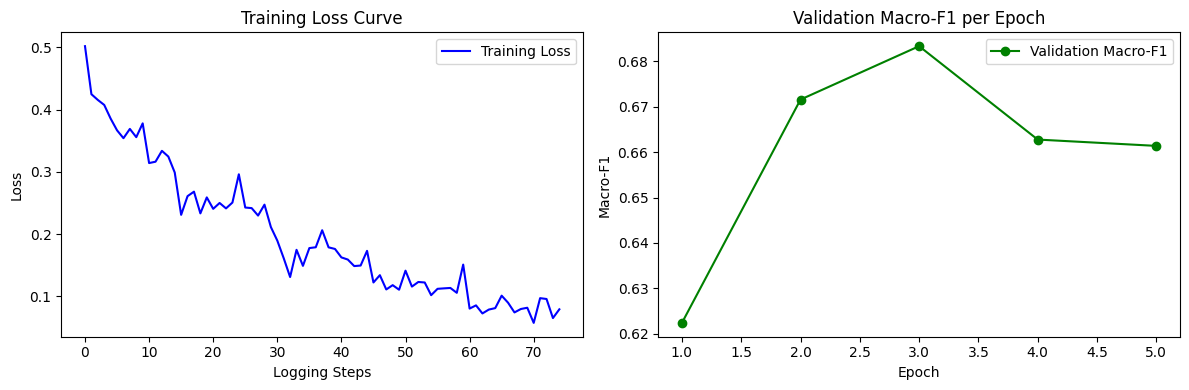

Đã lưu đồ thị học tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint06_lr/learning_curves_checkpoint06.png


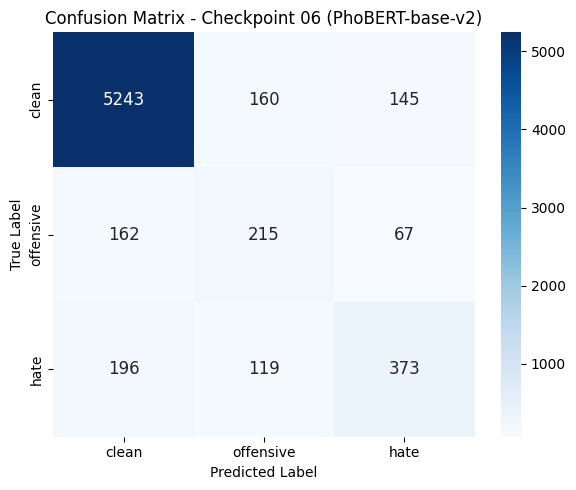

Đã lưu ma trận nhầm lẫn tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint06_lr/confusion_matrix_checkpoint06.png


In [12]:
curves_output_path = os.path.join(outputs_dir, 'learning_curves_checkpoint06.png')
cm_output_path = os.path.join(outputs_dir, 'confusion_matrix_checkpoint06.png')

import matplotlib.pyplot as plt
import seaborn as sns

log_history = trainer.state.log_history
train_loss = [x['loss'] for x in log_history if 'loss' in x]
eval_f1 = [x['eval_macro_f1'] for x in log_history if 'eval_macro_f1' in x]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
if train_loss:
    ax1.plot(train_loss, label='Training Loss', color='blue')
    ax1.set_title('Training Loss Curve')
    ax1.set_xlabel('Logging Steps')
    ax1.set_ylabel('Loss')
    ax1.legend()
if eval_f1:
    ax2.plot(range(1, len(eval_f1) + 1), eval_f1, label='Validation Macro-F1', color='green', marker='o')
    ax2.set_title('Validation Macro-F1 per Epoch')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Macro-F1')
    ax2.legend()
plt.tight_layout()
plt.savefig(curves_output_path, dpi=300)
plt.show()
print(f'Đã lưu đồ thị học tại: {curves_output_path}')

df_cm = pd.DataFrame(results['confusion_matrix'], index=class_names, columns=class_names)
fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
sns.heatmap(df_cm, annot=True, cmap='Blues', fmt='d', cbar=True, ax=ax_cm, annot_kws={'size': 12})
ax_cm.set_title('Confusion Matrix - Checkpoint 06 (PhoBERT-base-v2)')
ax_cm.set_xlabel('Predicted Label')
ax_cm.set_ylabel('True Label')
plt.tight_layout()
plt.savefig(cm_output_path, dpi=300)
plt.show()
print(f'Đã lưu ma trận nhầm lẫn tại: {cm_output_path}')

## 10. Xuất Các Tệp Kết Quả Chuẩn Hóa (Mandatory Artifacts Export)

In [14]:
predictions_csv_path = os.path.join(outputs_dir, 'predictions.csv')
scores_csv_path = os.path.join(outputs_dir, 'evaluation_scores.csv')
report_csv_path = os.path.join(outputs_dir, 'classification_report.csv')
cm_csv_path = os.path.join(outputs_dir, 'confusion_matrix.csv')

test_ids = list(range(len(test_y)))

df_predictions = pd.DataFrame({
    'id': test_ids,
    'text': test_X,
    'ground_truth': y_true,
    'predicted_label': y_pred,
})
df_predictions.to_csv(predictions_csv_path, index=False, encoding='utf-8')
print(f'1. Đã xuất tệp dự đoán: {predictions_csv_path}')

df_cm = pd.DataFrame(results['confusion_matrix'], index=class_names, columns=class_names)
df_cm.index.name = 'true_label'
df_cm.to_csv(cm_csv_path)
print(f'2. Đã xuất tệp dữ liệu ma trận nhầm lẫn: {cm_csv_path}')

acc_val = round(float(results.get('accuracy', accuracy_score(y_true, y_pred))), 4)
macro_p_val = round(float(results.get('macro_precision', precision_score(y_true, y_pred, average='macro', zero_division=0))), 4)
macro_r_val = round(float(results.get('macro_recall', recall_score(y_true, y_pred, average='macro', zero_division=0))), 4)
per_class_p = results.get('per_class_precision', {name: round(precision_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})
per_class_r = results.get('per_class_recall', {name: round(recall_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})

scores_summary = {
    'metric': [
        'accuracy',
        'macro_precision',
        'macro_recall',
        'macro_f1',
        'micro_f1',
        'precision_clean',
        'recall_clean',
        'f1_clean',
        'precision_offensive',
        'recall_offensive',
        'f1_offensive',
        'precision_hate',
        'recall_hate',
        'f1_hate',
    ],
    'value': [
        acc_val,
        macro_p_val,
        macro_r_val,
        round(results['macro_f1'], 4),
        round(results['micro_f1'], 4),
        round(per_class_p['clean'], 4),
        round(per_class_r['clean'], 4),
        round(results['per_class_f1']['clean'], 4),
        round(per_class_p['offensive'], 4),
        round(per_class_r['offensive'], 4),
        round(results['per_class_f1']['offensive'], 4),
        round(per_class_p['hate'], 4),
        round(per_class_r['hate'], 4),
        round(results['per_class_f1']['hate'], 4),
    ],
}
df_scores = pd.DataFrame(scores_summary)
df_scores.to_csv(scores_csv_path, index=False)
print(f'3. Đã xuất tệp điểm số tổng hợp: {scores_csv_path}')

report_dict = classification_report(y_true, y_pred, target_names=class_names, digits=4, output_dict=True)
accuracy_val = report_dict.pop('accuracy')

rows = []
for label in class_names:
    row = report_dict[label]
    rows.append({
        'class': label,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support']),
    })

rows.append({
    'class': 'accuracy',
    'precision': None,
    'recall': None,
    'f1_score': round(accuracy_val, 4),
    'support': len(y_true),
})

for avg_type in ['macro avg', 'weighted avg']:
    row = report_dict[avg_type]
    rows.append({
        'class': avg_type,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support']),
    })

df_report = pd.DataFrame(rows)
df_report.to_csv(report_csv_path, index=False)
print(f'4. Đã xuất tệp báo cáo phân loại chi tiết: {report_csv_path}')

1. Đã xuất tệp dự đoán: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint06_lr/predictions.csv
2. Đã xuất tệp dữ liệu ma trận nhầm lẫn: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint06_lr/confusion_matrix.csv
3. Đã xuất tệp điểm số tổng hợp: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint06_lr/evaluation_scores.csv
4. Đã xuất tệp báo cáo phân loại chi tiết: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint06_lr/classification_report.csv
